In [10]:
import numpy as np
import pandas as pd
import tensorflow as tf
import json
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils import class_weight


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

import nltk
from nltk.stem import WordNetLemmatizer


import matplotlib as plt

In [11]:
data = pd.read_csv('../data/blooms_taxonomy_dataset.csv', encoding='latin-1')

data["Questions"] = data["Questions"].str.lower().str.replace(r'[^\w\s]', '', regex=True)

X = data["Questions"]
y = data["Category"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(np.unique(y_encoded))

print(f"Detected {num_classes} classes: {label_encoder.classes_}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

Detected 6 classes: ['BT1' 'BT2' 'BT3' 'BT4' 'BT5' 'BT6']


In [12]:
vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1,3))
X_train_tfidf = vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = vectorizer.transform(X_test).toarray()




In [13]:
model = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.01), input_shape=(X_train_tfidf.shape[1],)),
    BatchNormalization(),
    Dropout(0.6),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    BatchNormalization(),
    Dropout(0.6),
    Dense(num_classes, activation='softmax')
])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [15]:
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
dict_weights = dict(enumerate(weights))

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training Bloom's Taxonomy Model...")
history = model.fit(
    X_train_tfidf, y_train,
    epochs=20,
    validation_data=(X_test_tfidf, y_test),
    callbacks=[early_stop],
    class_weight=dict_weights,
    verbose=1
)

Training Bloom's Taxonomy Model...
Epoch 1/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4041 - loss: 3.7773 - val_accuracy: 0.6138 - val_loss: 3.0236
Epoch 2/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6741 - loss: 2.4413 - val_accuracy: 0.8327 - val_loss: 1.9253
Epoch 3/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7642 - loss: 1.8947 - val_accuracy: 0.8465 - val_loss: 1.5452
Epoch 4/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8047 - loss: 1.5089 - val_accuracy: 0.8468 - val_loss: 1.2734
Epoch 5/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8217 - loss: 1.2361 - val_accuracy: 0.8603 - val_loss: 1.0837
Epoch 6/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8356 - loss: 1.0534 - val_accuracy: 0.8650 - val_loss: 0.9554
Epoch 7/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8411 - loss: 0.9261 - val_accuracy: 0.8620 - val_loss: 0.8783
Epoch 8/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.846

In [16]:

with open('../data/co_mapping.json', 'r') as f:
    config = json.load(f)
print("done")


done


In [17]:
def analyze_question(question_text):
    clean_q = re.sub(r'[^\w\s]', '', question_text.lower())
    bloom_level = label_encoder.inverse_transform([np.argmax(model.predict(
        vectorizer.transform([clean_q]).toarray(), verbose=0))])[0]

    def get_best_match(items):
        if not items: return "N/A", 0
        match = max(items.items(), key=lambda x: sum(kw.lower() in clean_q for kw in x[1]['keywords']), default=("N/A", 0))
        score = sum(kw.lower() in clean_q for kw in match[1]['keywords']) if isinstance(match[1], dict) else 0
        return (match[0], score) if score > 0 else ("N/A", 0)

    subject, sub_score = get_best_match(config.get('subjects', {}))
    co_id, _ = get_best_match(config.get('co_mappings', {}).get(subject, {})) if sub_score > 0 else ("N/A", 0)

    return {
        "original_question": question_text,
        "bloom_level": bloom_level,
        "subject": subject if sub_score > 0 else "General/Unknown",
        "co_id": co_id
    }


In [18]:
loss, accuracy = model.evaluate(X_test_tfidf, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 516us/step - accuracy: 0.8606 - loss: 0.7282
Test Accuracy: 86.06%


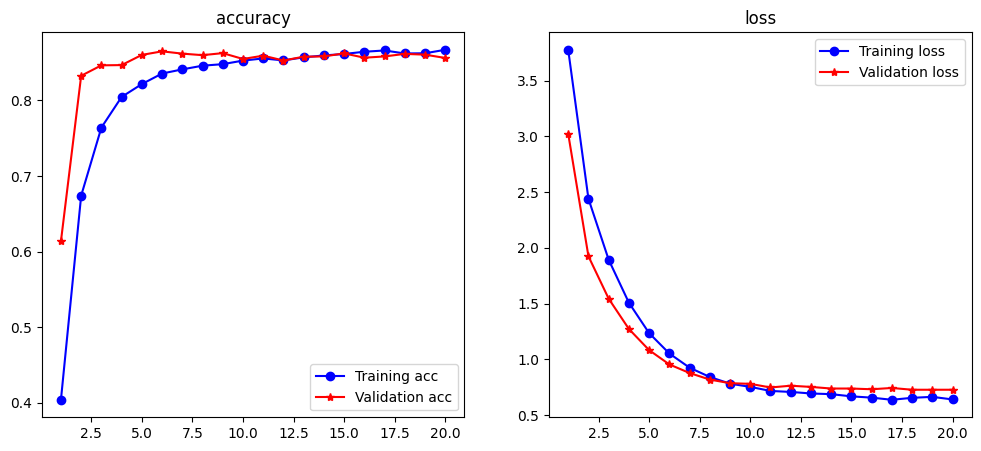

In [19]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title('accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title('loss')
    plt.legend()

    plt.show()

plot_history(history)